# Late Fusion 가중치 산출 노트북

## 배경
세 모달(후각/변비, 손그림 이미지, 운동학)이 **서로 다른 데이터셋**으로 학습됐기 때문에
공통 피험자 기반의 메타 모델 학습이 불가능합니다.

대신 각 모달의 **교차검증 AUC를 기반으로 가중치를 자동 산출**합니다.
이는 모델 성능이 높을수록 더 많은 신뢰를 부여하는 근거 있는 방식입니다.

## 각 모달 AUC (노트북 실행 결과)
| 모달 | 노트북 | AUC |
|---|---|---|
| 후각/변비 | PPMI.ipynb (XGBoost 5-Fold CV) | 0.775 |
| 손그림 이미지 | drawing_pipeline.ipynb (Holdout) | 0.8133 |
| 운동학 | kinematic_pipeline.ipynb (5-Fold 평균) | 0.7615 |

In [ ]:
import numpy as np
import json
import os

# ============================================================
# 1. 각 모달 AUC 입력
#    노트북 실행 결과에서 확인한 값을 여기에 입력하세요.
# ============================================================
AUC_OLF = 0.775   # PPMI.ipynb - XGBoost 5-Fold CV AUC
AUC_IMG = 0.8133  # drawing_pipeline.ipynb - Holdout AUC
AUC_KIN = 0.7615  # kinematic_pipeline.ipynb - 5-Fold 평균 AUC

# ============================================================
# 2. AUC 기반 가중치 자동 계산 (정규화)
# ============================================================
total_auc = AUC_OLF + AUC_IMG + AUC_KIN #2.3498

W_OLF = AUC_OLF / total_auc # 0.330
W_IMG = AUC_IMG / total_auc #0.346
W_KIN = AUC_KIN / total_auc #0.324

print('=' * 45)
print('  Late Fusion 가중치 (AUC 기반 자동 산출)')
print('=' * 45)
print(f'  후각/변비  (AUC={AUC_OLF:.4f}): {W_OLF:.4f}  ({W_OLF*100:.1f}%)')
print(f'  손그림CNN  (AUC={AUC_IMG:.4f}): {W_IMG:.4f}  ({W_IMG*100:.1f}%)')
print(f'  운동학     (AUC={AUC_KIN:.4f}): {W_KIN:.4f}  ({W_KIN*100:.1f}%)')
print(f'  합계:                      {W_OLF+W_IMG+W_KIN:.4f}')
print('=' * 45)

  Late Fusion 가중치 (AUC 기반 자동 산출)
  후각/변비  (AUC=0.7750): 0.3298  (33.0%)
  손그림CNN  (AUC=0.8133): 0.3461  (34.6%)
  운동학     (AUC=0.7615): 0.3241  (32.4%)
  합계:                      1.0000


In [2]:
# ============================================================
# 3. 가중치를 JSON 파일로 저장
#    kiosk.py에서 이 파일을 로드해서 사용합니다.
# ============================================================
fusion_config = {
    'method': 'auc_weighted_average',
    'weights': {
        'olf': round(W_OLF, 6),
        'img': round(W_IMG, 6),
        'kin': round(W_KIN, 6),
    },
    'auc_scores': {
        'olf': AUC_OLF,
        'img': AUC_IMG,
        'kin': AUC_KIN,
    },
    'description': {
        'olf': 'PPMI BSIT12+SCOPA - XGBoost 5-Fold CV',
        'img': 'Spiral drawing CNN (MobileNetV2) - Holdout',
        'kin': 'UCI+PaHaW kinematic RF - 5-Fold CV mean',
    }
}

SAVE_PATH = 'fusion_config.json'
with open(SAVE_PATH, 'w', encoding='utf-8') as f:
    json.dump(fusion_config, f, indent=2, ensure_ascii=False)

print(f'저장 완료: {SAVE_PATH}')
print(json.dumps(fusion_config, indent=2, ensure_ascii=False))

저장 완료: fusion_config.json
{
  "method": "auc_weighted_average",
  "weights": {
    "olf": 0.329815,
    "img": 0.346115,
    "kin": 0.32407
  },
  "auc_scores": {
    "olf": 0.775,
    "img": 0.8133,
    "kin": 0.7615
  },
  "description": {
    "olf": "PPMI BSIT12+SCOPA - XGBoost 5-Fold CV",
    "img": "Spiral drawing CNN (MobileNetV2) - Holdout",
    "kin": "UCI+PaHaW kinematic RF - 5-Fold CV mean"
  }
}


In [3]:
# ============================================================
# 4. 가중치 검증 - 임의 확률값으로 Fusion 동작 확인
# ============================================================
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus'] = False

def late_fusion(p_olf, p_img, p_kin, weights):
    """AUC 기반 가중 평균 Late Fusion"""
    score = (
        p_olf * weights['olf'] +
        p_img * weights['img'] +
        p_kin * weights['kin']
    )
    return float(np.clip(score, 0.0, 1.0))

weights = fusion_config['weights']

# 시나리오 검증
scenarios = [
    ('정상인 (모두 낮음)',    0.10, 0.15, 0.12),
    ('경계 (중간)',           0.45, 0.50, 0.40),
    ('고위험 (모두 높음)',    0.85, 0.90, 0.80),
    ('후각만 이상',           0.80, 0.20, 0.15),
    ('그림만 이상',           0.15, 0.85, 0.20),
    ('운동학만 이상',         0.15, 0.20, 0.85),
]

print(f'{"": <22} {"p_olf":>8} {"p_img":>8} {"p_kin":>8} {"최종위험도":>10}')
print('-' * 62)
for name, p_olf, p_img, p_kin in scenarios:
    risk = late_fusion(p_olf, p_img, p_kin, weights)
    print(f'{name: <22} {p_olf:>8.2f} {p_img:>8.2f} {p_kin:>8.2f} {risk*100:>9.1f}%')

                          p_olf    p_img    p_kin      최종위험도
--------------------------------------------------------------
정상인 (모두 낮음)                0.10     0.15     0.12      12.4%
경계 (중간)                    0.45     0.50     0.40      45.1%
고위험 (모두 높음)                0.85     0.90     0.80      85.1%
후각만 이상                     0.80     0.20     0.15      38.2%
그림만 이상                     0.15     0.85     0.20      40.8%
운동학만 이상                    0.15     0.20     0.85      39.4%


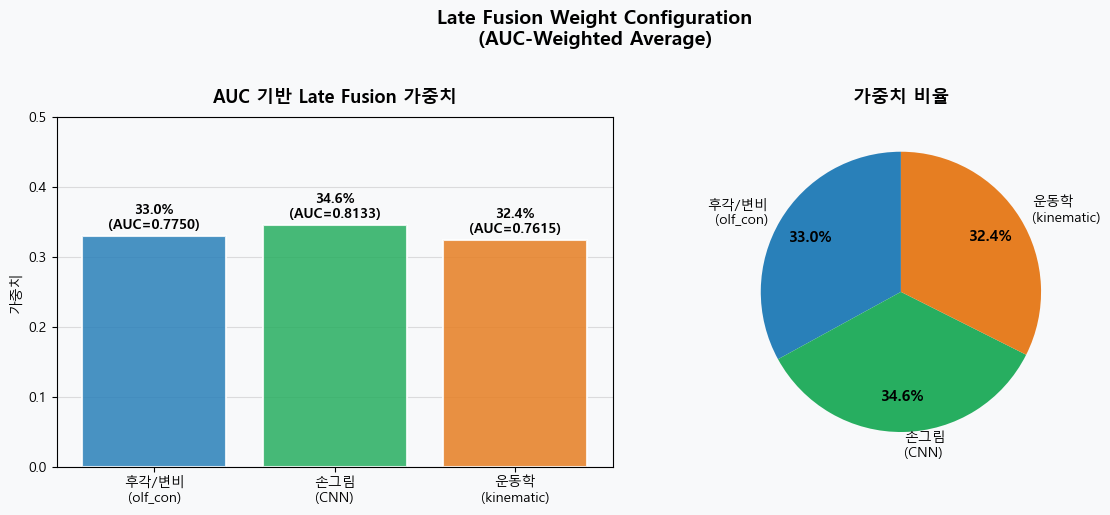

저장 완료: fusion_weights.png


In [4]:
# ============================================================
# 5. 가중치 시각화
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor='#F8F9FA')

# (a) 가중치 막대그래프
ax = axes[0]
labels  = ['후각/변비\n(olf_con)', '손그림\n(CNN)', '운동학\n(kinematic)']
w_vals  = [W_OLF, W_IMG, W_KIN]
auc_vals = [AUC_OLF, AUC_IMG, AUC_KIN]
colors  = ['#2980B9', '#27AE60', '#E67E22']

bars = ax.bar(labels, w_vals, color=colors, alpha=0.85,
              edgecolor='white', linewidth=1.5)
for bar, w, auc in zip(bars, w_vals, auc_vals):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.005,
            f'{w*100:.1f}%\n(AUC={auc:.4f})',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, 0.5)
ax.set_title('AUC 기반 Late Fusion 가중치', fontsize=13, fontweight='bold', pad=10)
ax.set_ylabel('가중치')
ax.set_facecolor('#F8F9FA')
ax.yaxis.grid(True, alpha=0.4)
ax.set_axisbelow(True)

# (b) 파이 차트
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    w_vals,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
)
for t in autotexts:
    t.set_fontsize(11)
    t.set_fontweight('bold')
ax2.set_title('가중치 비율', fontsize=13, fontweight='bold', pad=10)

plt.suptitle('Late Fusion Weight Configuration\n(AUC-Weighted Average)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fusion_weights.png', dpi=150, bbox_inches='tight')
plt.show()
print('저장 완료: fusion_weights.png')

## kiosk.py 적용 방법

`fusion_config.json`을 `modeling/` 폴더에 복사한 뒤, `kiosk.py`에서 아래와 같이 로드합니다.

```python
# load_models() 함수 안에 추가
import json
with open(mp / 'fusion_config.json', 'r') as f:
    fusion_cfg = json.load(f)
weights = fusion_cfg['weights']  # {'olf': 0.330, 'img': 0.346, 'kin': 0.324}

# Step 4 결과 계산 부분
final_risk = float(np.clip(
    p_olf * weights['olf'] +
    p_img * weights['img'] +
    p_kin * weights['kin'],
    0.0, 1.0
))
```